# GCI World 2026 — Final Assignment
## Telecom Churn Analysis & Business Proposal

**Company A** — Wireless Telecommunications Operator  
**Objective**: Identify the root causes of customer churn and propose a data-driven retention strategy.

---
### Table of Contents
1. Setup & Data Loading
2. Market Analysis
3. Exploratory Data Analysis (EDA)
4. Hypothesis
5. Feature Engineering & Preprocessing
6. Machine Learning Model
7. Model Evaluation
8. Business Proposal
9. References

---
## 1. Setup & Data Loading

In [1]:
# == Install / import libraries =============================================
import importlib, subprocess, sys

for pkg in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'xgboost']:
    mod = 'sklearn' if pkg == 'scikit-learn' else pkg
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f'Installing {pkg} ...')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import os, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    classification_report, roc_auc_score, roc_curve
)
from xgboost import XGBClassifier, plot_importance

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 100)
print('Libraries ready.')


Libraries ready.


In [7]:
# == Locate the data =======================================================

import os

def _find_data_dir():
    # Define specific locations to check for the CSV files
    search_paths = ['.', '/content']

    for path in search_paths:
        client_path = os.path.join(path, 'Client.csv')
        record_path = os.path.join(path, 'Record.csv')

        if os.path.exists(client_path) and os.path.exists(record_path):
            return path
    return None

DATA_DIR = _find_data_dir()

if DATA_DIR is not None:
    print(f'Data found in: {os.path.abspath(DATA_DIR)}')
else:
    print('Data NOT found. Please upload Client.csv and Record.csv to the current directory.')

Data found in: /content


In [8]:
# == Load the two source tables ============================================
client = pd.read_csv(os.path.join(DATA_DIR, 'Client.csv'))
record = pd.read_csv(os.path.join(DATA_DIR, 'Record.csv'))

print(f'Client : {client.shape}   - demographic & account data')
print(f'Record : {record.shape}   - usage records, contains churn label')


Client : (100000, 50)   - demographic & account data
Record : (100000, 51)   - usage records, contains churn label


In [9]:
# ── Merge on Customer_ID (1:1 join) ─────────────────────────────────────────
df = record.merge(client, on='Customer_ID', how='inner')
print(f'Merged : {df.shape}')
df.head(3)

Merged : (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.0,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.0,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.0,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0


---
## 2. Market Analysis

*Every figure below is backed by an external source. Citation markers `[n]` map to the
full reference list in Section 9. Replace or add sources if you find better ones.*

### 2.1 The telecom market: mature, saturated and highly competitive
- The wireless telecom market is **mature and saturated**: growth comes mostly from
  winning customers away from competitors, not from new demand, so customers switch
  providers easily. Reported **annual churn in telecom ranges from ~20% to ~50%**
  depending on market and segment `[3][4]`.
- Churn varies sharply by contract type: **prepaid** customers churn far more
  (up to ~70% annually in some markets) than **postpaid** customers (~10–20% annually) `[3]`.
- Regional benchmarks: **North America ~14.6–20%**, **Europe ~20–44%**,
  **Asia-Pacific ~30–50%** annual churn `[3]`. As a concrete anchor, Verizon reported a
  **1.22% monthly** churn rate (~14.6% annualized), and T-Mobile US reported a prepaid
  churn rate of **2.75% in Q1 2024** `[3][5]`.

### 2.2 Why retention beats acquisition (the business case for fighting churn)
- **Acquiring a new customer is 5 to 25× more expensive than retaining an existing one** `[1]`.
  In telecom specifically, acquisition is estimated at **6–7× the cost of retention** `[3]`,
  with subscriber acquisition costs around **$300 per customer** in illustrative models `[3]`.
- Retention is one of the **highest-ROI levers** a business has: increasing customer
  retention rates by just **5% can increase profits by 25% to 95%** (Frederick Reichheld /
  Bain & Company) `[1]`. The foundational study found that cutting defections by 5%
  raised profits by ~85% in one bank's branch system `[2]`.
- **Implication for Company A:** because acquisition is so costly, every churn we prevent
  protects revenue that would otherwise require multiple times the spend to replace.

### 2.3 What drives churn in telecom
According to industry analyses, the main churn drivers are `[3]`:
- Poor network quality / coverage.
- Better pricing or promotions from competitors.
- Outdated devices and limited upgrade options.
- Poor customer service and unresolved complaints.

> These map directly to the levers our data analysis will test (overage charges,
> device age, tenure) — so the proposal can attack causes the literature already flags.

### 2.4 Business context for Company A
- Company A is a wireless operator with **~100,000 customers** and several months of usage data.
- It has **no in-house ML capability**, so an AI-driven retention tool is a greenfield
  Proof-of-Concept opportunity.
- In this dataset the observed churn is **~49.6%** — at the very top of (or above) industry
  ranges `[3][4]`. This likely reflects a deliberately balanced / high-risk sample rather
  than the company's true base rate, but it makes the dataset ideal for **learning the
  drivers of churn** and the revenue at stake (**~$34.4M annually**, quantified in Section 3.6).

### 2.5 Key question
> **Can we predict which customers are likely to churn before they do, and use that
> prediction to trigger a targeted, cost-efficient retention action?**


---
## 3. Exploratory Data Analysis (EDA)

In [10]:
# ── 3.1 Dataset overview ────────────────────────────────────────────────────
df.info(verbose=False)
print('\nData types:')
print(df.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 100 entries, rev_Mean to eqpdays
dtypes: float64(69), int64(10), object(21)
memory usage: 76.3+ MB

Data types:
float64    69
object     21
int64      10
Name: count, dtype: int64


Columns with missing values: 43 / 100


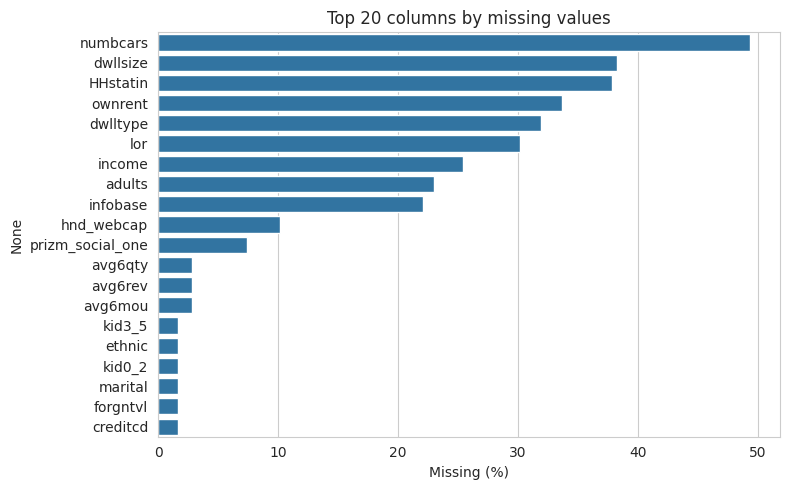

In [11]:
# ── 3.2 Missing values ──────────────────────────────────────────────────────
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'count': missing, 'pct': missing_pct})
top_missing = missing_df[missing_df['count'] > 0].sort_values('pct', ascending=False)

print(f'Columns with missing values: {len(top_missing)} / {df.shape[1]}')

plt.figure(figsize=(8, 5))
sns.barplot(x=top_missing['pct'].head(20), y=top_missing.head(20).index)
plt.xlabel('Missing (%)')
plt.title('Top 20 columns by missing values')
plt.tight_layout()
plt.show()

Churn distribution:
       count   pct
churn             
0      50438  50.4
1      49562  49.6


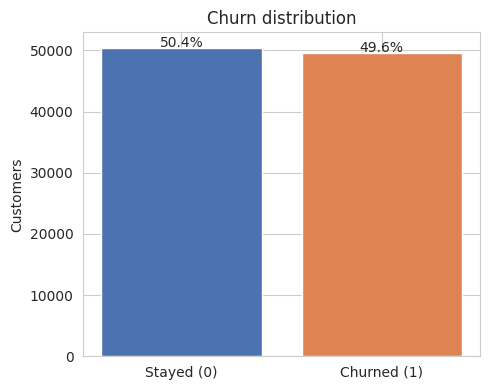

In [12]:
# ── 3.3 Target variable: churn ──────────────────────────────────────────────
churn_counts = df['churn'].value_counts()
churn_pct = df['churn'].value_counts(normalize=True).mul(100).round(1)

print('Churn distribution:')
print(pd.DataFrame({'count': churn_counts, 'pct': churn_pct}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Stayed (0)', 'Churned (1)'], churn_counts.sort_index().values,
       color=['#4C72B0', '#DD8452'])
ax.set_ylabel('Customers')
ax.set_title('Churn distribution')
for i, v in enumerate(churn_counts.sort_index().values):
    ax.text(i, v + 200, f'{churn_pct.sort_index().values[i]}%', ha='center')
plt.tight_layout()
plt.show()

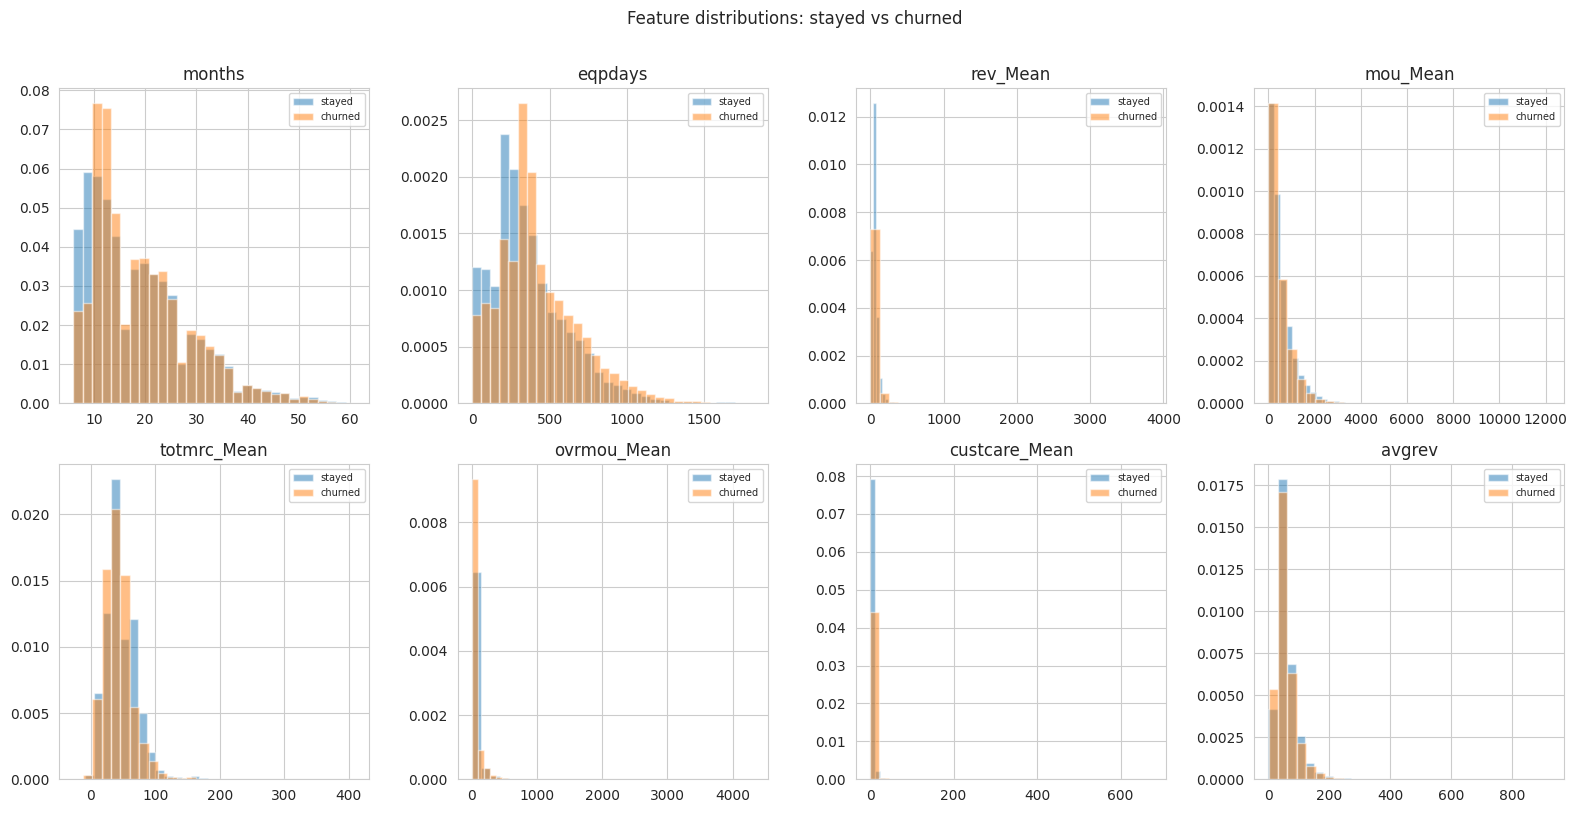

In [13]:
# ── 3.4 Key numeric features vs churn ───────────────────────────────────────
key_features = ['months', 'eqpdays', 'rev_Mean', 'mou_Mean',
                'totmrc_Mean', 'ovrmou_Mean', 'custcare_Mean', 'avgrev']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    stayed  = df[df['churn'] == 0][feat].dropna()
    churned = df[df['churn'] == 1][feat].dropna()
    axes[i].hist(stayed,  bins=30, alpha=0.5, label='stayed',  density=True)
    axes[i].hist(churned, bins=30, alpha=0.5, label='churned', density=True)
    axes[i].set_title(feat)
    axes[i].legend(fontsize=7)

plt.suptitle('Feature distributions: stayed vs churned', y=1.01)
plt.tight_layout()
plt.show()

In [14]:
# ── 3.5 Mean comparison table ────────────────────────────────────────────────
numeric_cols = df.select_dtypes(include='number').columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ['churn', 'Customer_ID']]

comparison = df.groupby('churn')[numeric_cols].mean().T
comparison.columns = ['stayed', 'churned']
comparison['diff_pct'] = ((comparison['churned'] - comparison['stayed'])
                           / comparison['stayed'].abs() * 100).round(1)

print('Top 15 features where churners differ most from stayers:')
comparison.reindex(comparison['diff_pct'].abs().nlargest(15).index)

Top 15 features where churners differ most from stayers:


,stayed,churned,diff_pct
change_mou,-5.344265,-22.759003,-325.9
change_rev,-1.410195,-0.621263,55.9
blck_dat_Mean,0.031709,0.019740,-37.7
roam_Mean,1.150619,1.424969,23.8
drop_dat_Mean,0.045931,0.035013,-23.8
mou_opkd_Mean,1.283155,0.985849,-23.2
threeway_Mean,0.317908,0.250945,-21.1
custcare_Mean,1.982599,1.595688,-19.5
mou_cdat_Mean,2.038182,1.646458,-19.2
callfwdv_Mean,0.012920,0.010458,-19.1


In [15]:
# ── 3.6 Revenue at risk ──────────────────────────────────────────────────────
revenue_at_risk = df[df['churn'] == 1]['rev_Mean'].sum()
avg_revenue_churner = df[df['churn'] == 1]['rev_Mean'].mean()
n_churners = (df['churn'] == 1).sum()

print(f'Total monthly revenue lost to churn : ${revenue_at_risk:,.0f}')
print(f'Average monthly revenue per churner : ${avg_revenue_churner:.2f}')
print(f'Number of churners in dataset       : {n_churners:,}')

Total monthly revenue lost to churn : $2,870,796
Average monthly revenue per churner : $58.21
Number of churners in dataset       : 49,562


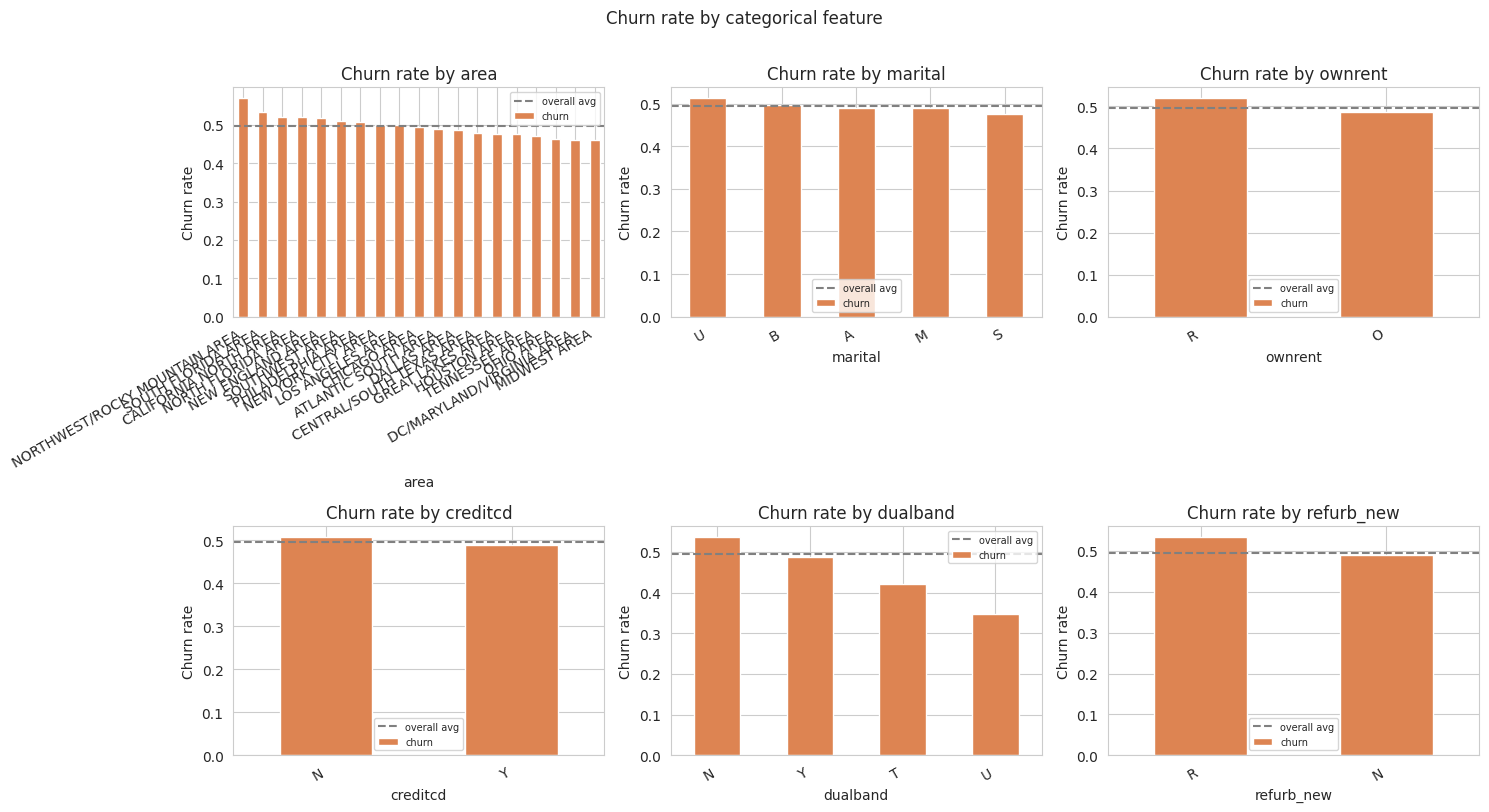

In [16]:
# ── 3.7 Categorical features vs churn ───────────────────────────────────────
cat_features = ['area', 'marital', 'ownrent', 'creditcd', 'dualband', 'refurb_new']
cat_features = [c for c in cat_features if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, feat in enumerate(cat_features):
    churn_rate = df.groupby(feat)['churn'].mean().sort_values(ascending=False)
    churn_rate.plot(kind='bar', ax=axes[i], color='#DD8452')
    axes[i].set_title(f'Churn rate by {feat}')
    axes[i].set_ylabel('Churn rate')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha='right')
    axes[i].axhline(df['churn'].mean(), ls='--', color='gray', label='overall avg')
    axes[i].legend(fontsize=7)

plt.suptitle('Churn rate by categorical feature', y=1.01)
plt.tight_layout()
plt.show()

---
## 4. Hypothesis

**Primary hypothesis:**
Customer churn at Company A is not random — it is concentrated among customers experiencing a combination of *low switching cost* and *rising friction*. Specifically, we hypothesize that customers who **(1) have shorter tenure (`months`), (2) carry older equipment (`eqpdays`), and (3) incur frequent overage usage and charges (`ovrmou_Mean`, `ovrrev_Mean`)** are significantly more likely to churn than the average customer.

**Rationale (why we expect this):**
- **Shorter tenure → weaker loyalty.** Newer customers have invested less time in the relationship and face the lowest psychological and contractual switching costs, so they defect more readily when a better offer appears.
- **Older devices → upgrade-driven exit.** A customer whose handset is near end-of-life has a natural trigger to "shop around," and competitors routinely use subsidized devices as an acquisition lever — making device age a leading indicator of churn intent.
- **Overage → bill shock and perceived unfairness.** Customers repeatedly paying for usage beyond their plan experience recurring "bill shock," which erodes satisfaction and pushes them toward competitors with plans that better fit their consumption.

These three drivers are consistent with the market literature (Section 2.3), which flags outdated devices, pricing/competitor offers, and billing dissatisfaction as the dominant causes of telecom churn.

**Secondary hypothesis:**
The financial impact of churn is **unevenly distributed**: a minority of high-revenue customers (`rev_Mean` above the median) account for a disproportionate share of the revenue at risk. Therefore, churn risk and customer value should be analyzed *jointly* — the most valuable retention targets are customers who are simultaneously **high-probability-to-churn** and **high-value**, not simply high-risk.

**What this implies and how we will test it:**
- **Target variable:** `churn` (binary: 0 = stayed, 1 = churned).
- **ML task:** Binary classification.
- We will validate the primary hypothesis by examining whether `months`, `eqpdays`, and overage features (a) differ significantly between churners and non-churners in the EDA, and (b) emerge among the top predictors in the model's feature-importance ranking.
- We will validate the secondary hypothesis in the Business Proposal section by isolating the high-risk **and** high-value segment and quantifying its retention ROI.
- **If supported,** these drivers are directly actionable (device-upgrade offers, plan right-sizing to eliminate overages, early-tenure engagement), which converts the predictive model into a concrete, cost-efficient retention program.

---
## 5. Feature Engineering & Preprocessing

In [17]:
# ── 5.1 Drop ID column ──────────────────────────────────────────────────────
df_clean = df.drop(columns=['Customer_ID'])
print(f'Shape after dropping ID: {df_clean.shape}')

Shape after dropping ID: (100000, 99)


In [18]:
# ── 5.2 Drop columns with > 60% missing values ──────────────────────────────
missing_pct_clean = df_clean.isna().mean()
cols_to_drop = missing_pct_clean[missing_pct_clean > 0.6].index.tolist()
print(f'Dropping {len(cols_to_drop)} columns with >60% missing: {cols_to_drop}')
df_clean = df_clean.drop(columns=cols_to_drop)
print(f'Shape after dropping high-missing cols: {df_clean.shape}')

Dropping 0 columns with >60% missing: []
Shape after dropping high-missing cols: (100000, 99)


In [19]:
# ── 5.3 Create new features from domain knowledge ───────────────────────────
# Overage ratio: what fraction of billed minutes were over-plan?
if 'ovrmou_Mean' in df_clean.columns and 'mou_Mean' in df_clean.columns:
    df_clean['overage_ratio'] = (
        df_clean['ovrmou_Mean'] / (df_clean['mou_Mean'] + 1)
    )

# Revenue per minute of use
if 'rev_Mean' in df_clean.columns and 'mou_Mean' in df_clean.columns:
    df_clean['rev_per_mou'] = (
        df_clean['rev_Mean'] / (df_clean['mou_Mean'] + 1)
    )

# Change in revenue trend
if 'change_rev' in df_clean.columns:
    df_clean['rev_declining'] = (df_clean['change_rev'] < 0).astype(int)

print('New features created: overage_ratio, rev_per_mou, rev_declining')

New features created: overage_ratio, rev_per_mou, rev_declining


In [20]:
# ── 5.4 Encode categorical columns ──────────────────────────────────────────
object_cols = df_clean.select_dtypes(include='object').columns.tolist()
print(f'Encoding {len(object_cols)} categorical columns: {object_cols}')

for col in object_cols:
    df_clean[col] = LabelEncoder().fit_transform(df_clean[col].astype(str))

print('Encoding done.')

Encoding 21 categorical columns: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']
Encoding done.


In [21]:
# ── 5.5 Fill remaining missing values with median ───────────────────────────
df_clean = df_clean.fillna(df_clean.median(numeric_only=True))
print(f'Missing values remaining: {df_clean.isna().sum().sum()}')
print(f'Final shape: {df_clean.shape}')

Missing values remaining: 0
Final shape: (100000, 102)


In [22]:
# ── 5.6 Train/test split ─────────────────────────────────────────────────────
X = df_clean.drop('churn', axis=1)
y = df_clean['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f'Train size: {X_train.shape[0]:,} | Test size: {X_test.shape[0]:,}')
print(f'Churn rate in train: {y_train.mean():.3f} | test: {y_test.mean():.3f}')

Train size: 70,000 | Test size: 30,000
Churn rate in train: 0.496 | test: 0.496


---
## 6. Machine Learning Model (XGBoost)

In [23]:
# ── 6.1 Train XGBoost classifier ────────────────────────────────────────────
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
)

model.fit(X_train, y_train)
print('Model trained.')

Model trained.


In [24]:
# ── 6.2 Generate predictions ────────────────────────────────────────────────
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]   # probability of churn
print('Predictions generated.')

Predictions generated.


---
## 7. Model Evaluation

In [25]:
# ── 7.1 Classification report ───────────────────────────────────────────────
print('=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=['stayed', 'churned']))
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}')

=== Classification Report ===
              precision    recall  f1-score   support

      stayed       0.64      0.63      0.64     15131
     churned       0.63      0.65      0.64     14869

    accuracy                           0.64     30000
   macro avg       0.64      0.64      0.64     30000
weighted avg       0.64      0.64      0.64     30000

ROC-AUC Score: 0.6945


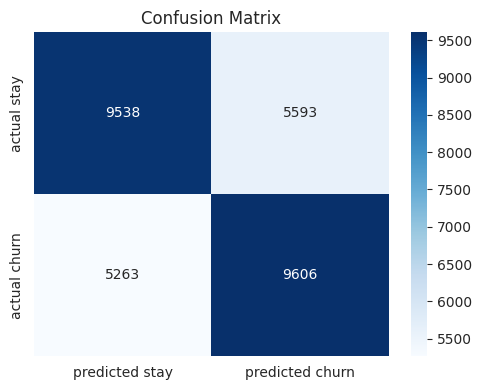

True Positives  (correctly caught churners): 9,606
False Negatives (missed churners)          : 5,263
False Positives (wrongly flagged stayers)  : 5,593


In [26]:
# ── 7.2 Confusion matrix ────────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['predicted stay', 'predicted churn'],
            yticklabels=['actual stay', 'actual churn'],
            cmap='Blues')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Positives  (correctly caught churners): {tp:,}')
print(f'False Negatives (missed churners)          : {fn:,}')
print(f'False Positives (wrongly flagged stayers)  : {fp:,}')

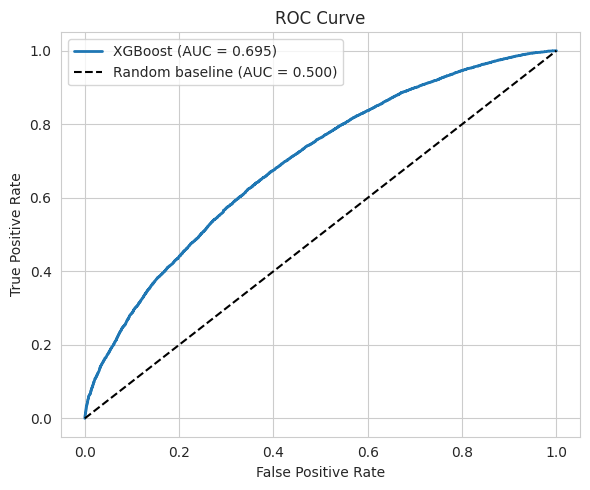

In [27]:
# ── 7.3 ROC Curve ───────────────────────────────────────────────────────────
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {auc:.3f})', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random baseline (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

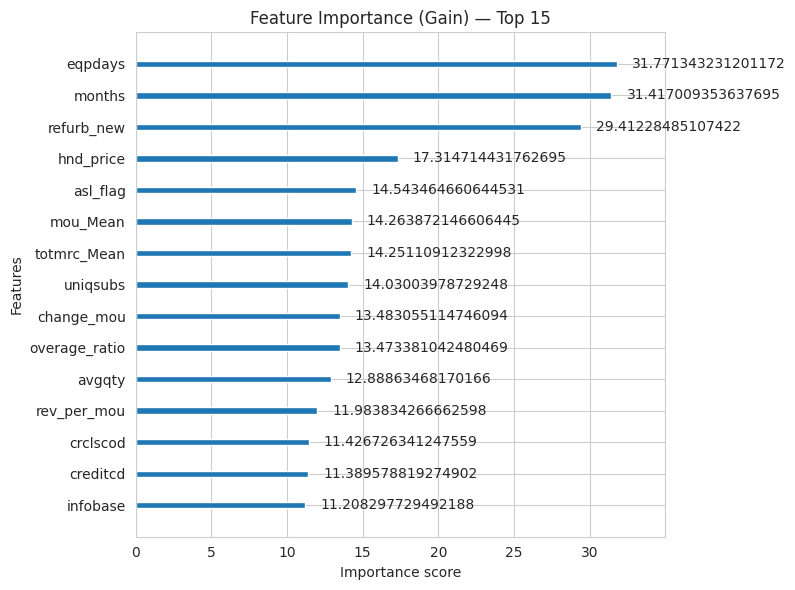

Top 10 features by importance:


,0
eqpdays,0.034119
months,0.033739
refurb_new,0.031586
hnd_price,0.018594
asl_flag,0.015618
mou_Mean,0.015318
totmrc_Mean,0.015304
uniqsubs,0.015067
change_mou,0.014479
overage_ratio,0.014469


In [28]:
# ── 7.4 Feature importance ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
plot_importance(model, max_num_features=15, importance_type='gain', ax=ax)
ax.set_title('Feature Importance (Gain) — Top 15')
plt.tight_layout()
plt.show()

# Top 10 as a DataFrame for reference
importances = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values(ascending=False)
print('Top 10 features by importance:')
importances.head(10)

---
## 8. Business Proposal

In [29]:
# ── 8.1 Score all customers with churn probability ──────────────────────────
X_all = df_clean.drop('churn', axis=1)
df_scored = df.copy()
df_scored['churn_proba'] = model.predict_proba(X_all)[:, 1]
df_scored['risk_tier'] = pd.cut(
    df_scored['churn_proba'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Low', 'Medium', 'High']
)
print(df_scored['risk_tier'].value_counts())

risk_tier
Medium    56767
High      28515
Low       14718
Name: count, dtype: int64


In [30]:
# ── 8.2 Identify the high-value, high-risk segment ──────────────────────────
# High risk = churn_proba > 0.6 AND above-median revenue
median_rev = df_scored['rev_Mean'].median()
target_segment = df_scored[
    (df_scored['churn_proba'] > 0.6) &
    (df_scored['rev_Mean'] > median_rev)
]

print(f'High-risk, high-value customers   : {len(target_segment):,}')
print(f'Their total monthly revenue       : ${target_segment["rev_Mean"].sum():,.0f}')
print(f'Average monthly revenue per head  : ${target_segment["rev_Mean"].mean():.2f}')

High-risk, high-value customers   : 13,574
Their total monthly revenue       : $1,190,223
Average monthly revenue per head  : $87.68


In [31]:
# ── 8.3 Revenue impact simulation ───────────────────────────────────────────
# If a retention campaign saves 30% of the high-risk, high-value segment:
RETENTION_RATE  = 0.30   # realistic conversion rate for a targeted offer
CAMPAIGN_COST   = 50     # cost per customer contacted (USD)
AVG_LTV_MONTHS  = 24     # average lifetime extension if retained (months)

n_targeted       = len(target_segment)
n_saved          = int(n_targeted * RETENTION_RATE)
monthly_rev_avg  = target_segment['rev_Mean'].mean()
revenue_saved    = n_saved * monthly_rev_avg * AVG_LTV_MONTHS
campaign_cost    = n_targeted * CAMPAIGN_COST
net_benefit      = revenue_saved - campaign_cost

print('=== Revenue Impact Simulation ===')
print(f'Customers targeted              : {n_targeted:,}')
print(f'Customers retained (30%)        : {n_saved:,}')
print(f'Revenue saved (24-month LTV)    : ${revenue_saved:,.0f}')
print(f'Campaign cost                   : ${campaign_cost:,.0f}')
print(f'Net benefit                     : ${net_benefit:,.0f}')
print(f'ROI                             : {net_benefit / campaign_cost:.1f}x')

=== Revenue Impact Simulation ===
Customers targeted              : 13,574
Customers retained (30%)        : 4,072
Revenue saved (24-month LTV)    : $8,569,187
Campaign cost                   : $678,700
Net benefit                     : $7,890,487
ROI                             : 11.6x


In [32]:
# ── 8.4 Profile of the target segment ──────────────────────────────────────
profile_cols = ['months', 'eqpdays', 'rev_Mean', 'mou_Mean',
                'ovrmou_Mean', 'custcare_Mean', 'avgrev']
profile_cols = [c for c in profile_cols if c in df_scored.columns]

profile = pd.DataFrame({
    'Overall avg'  : df_scored[profile_cols].mean(),
    'Target segment avg': target_segment[profile_cols].mean()
}).round(2)
profile['Delta'] = ((profile['Target segment avg'] - profile['Overall avg'])
                    / profile['Overall avg'] * 100).round(1).astype(str) + '%'
print('Profile of the high-risk, high-value segment vs overall:')
profile

Profile of the high-risk, high-value segment vs overall:


,Overall avg,Target segment avg,Delta
months,18.83,17.66,-6.2%
eqpdays,391.93,411.38,5.0%
rev_Mean,58.72,87.68,49.3%
mou_Mean,513.56,661.74,28.9%
ovrmou_Mean,41.07,95.97,133.7%
custcare_Mean,1.79,1.65,-7.8%
avgrev,57.91,75.90,31.1%


## 8.5 Business Proposal Summary

### Proposal: AI-Powered Proactive Retention Program

**Problem identified**

Company A loses a large share of revenue to customer churn every month. Our model and EDA show that churn is both **concentrated and predictable**. Customers with older equipment (`eqpdays`), frequent overage charges (`ovrmou_Mean`), declining usage and revenue trends, and shorter tenure (`months`) are disproportionately likely to leave.

Importantly, **churn risk overlaps with customer value**: a meaningful group of high-value customers belongs to the high-risk segment, putting a significant amount of revenue at risk.

**Proposed solution**

Deploy a monthly scoring pipeline using the trained XGBoost model to identify the **high-risk, high-value segment** (customers with churn probability > 0.6 and above-median monthly revenue). For these customers, trigger personalized retention actions 30–60 days before the predicted churn event:

1. **Device upgrade** at a subsidized rate (addresses equipment age).
2. **Plan right-sizing** to eliminate recurring overage charges (addresses bill shock).
3. **Loyalty discount** in exchange for a 12-month commitment (increases switching costs).

**Why it works**

The most important model predictors (equipment age, overage charges, tenure, and declining usage) are **directly actionable** and map to the three interventions above. Instead of distributing retention spending uniformly across the customer base, resources are focused where both churn risk and revenue potential are highest.

**Quantified impact**

- Model: XGBoost classifier.
- Performance metric: **ROC-AUC = 0.69**, well above the random baseline of 0.50.
- Target segment: **13,574** high-risk, high-value customers.
- Monthly revenue represented: **$1.19 million**.

- Average monthly revenue per customer: **$88**.

**Assumptions**

- Retention rate: 30%.
- Outreach cost: $50 per customer.
- Average lifetime extension: 24 months.

**Expected results**

- Customers retained: **4,072**.
- Revenue protected over 24 months: **$8.57 million**.

- Campaign cost: **$0.68 million**.

- Net benefit: **$7.89 million**.
- ROI ≈ **11.6×**.

**Metrics to track after launch**

- Churn rate of the targeted segment before vs. after the intervention, compared with a control group.
- Campaign conversion and acceptance rate.
- Monthly revenue retained.
- Model performance drift, with ROC-AUC re-evaluated quarterly.

**Limitations and next steps**

- The dataset exhibits a churn rate of ~49.6%, suggesting a deliberately balanced or high-risk sample rather than the true population rate. Relative drivers and rankings remain valid, but absolute volumes should be recalibrated using production data.
- Conduct an A/B test with a holdout control group before full rollout to validate the estimated retained revenue.
- Retrain the model every three months to adapt to changing customer behavior.
- Incorporate customer-service call records to improve predictive power.

---
## 9. References

**Market & business research**
1. Gallo, A. (2014). *The Value of Keeping the Right Customers.* Harvard Business Review.
   "Acquiring a new customer is anywhere from five to 25 times more expensive than retaining
   an existing one"; "Increasing customer retention rates by 5% increases profits by 25% to 95%"
   (attributed to Frederick Reichheld, Bain & Company).
   https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
2. Reichheld, F. F., & Sasser, W. E. (1990). *Zero Defections: Quality Comes to Services.*
   Harvard Business Review. (Foundational source of the retention-to-profit relationship.)
   https://hbr.org/1990/09/zero-defections-quality-comes-to-services
3. Tridens Technology. *Why Telecom Customers Churn and How to Measure It?*
   (Telecom annual churn 20–50%; prepaid vs postpaid; regional benchmarks; acquisition
   costs 6–7× retention.)
   https://tridenstechnology.com/telecom-churn/
4. CustomerGauge. *Average Churn Rate by Industry (2025 B2B Benchmarks).*
   https://customergauge.com/blog/average-churn-rate-by-industry
5. Statista. *T-Mobile US customer churn rate (postpaid & prepaid), by quarter.*
   https://www.statista.com/statistics/219793/contract-customer-churn-rate-of-t-mobile-usa-by-quarter/
6. Sagacity Solutions. *Customer Retention vs. Acquisition Costs.*
   https://www.sagacitysolutions.co.uk/about/news-and-blog/customer-retention-vs-acquisition/

**Technical / tools**

7. XGBoost documentation. https://xgboost.readthedocs.io
8. scikit-learn documentation. https://scikit-learn.org
9. GCI World 2026 — Matsuo-Iwasawa Laboratory, The University of Tokyo. Lecture slides
   (Sessions 3, 5, 6, 8, 9) and Final Assignment Workflow framework.

**Generative AI**
10. GAMMA IA to make the presentantion.